# Tarea 6: búsqueda tabú para el TSP

Se implementa la variante **basada en lo reciente**, de la presentación
9, y se compara con el templado simulado de la Tarea 5. Se usan 10, 15,
30 y 50 ciudades, con 20 rutas iniciales por tamaño.

Este archivo conserva una ejecución completa. Se puede abrir en Google
Colab y usar **Entorno de ejecución → Ejecutar todas**, con CPU. No
necesita Drive, credenciales ni archivos externos: incluye coordenadas,
algoritmos, referencia exacta y comparación. Se ejecutan de nuevo las
160 corridas; el tiempo depende del equipo. El informe Word/PDF usa los
tiempos de la primera ejecución local, guardada en el paquete; los
tiempos mostrados aquí corresponden a esta ejecución del notebook.

In [1]:
from pathlib import Path
from itertools import combinations, permutations
from array import array
import contextlib
import math
import random
import time
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CARPETA = Path('tarea6_resultados')
(CARPETA / 'datos').mkdir(parents=True, exist_ok=True)
(CARPETA / 'resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| pandas:', pd.__version__)

Python: 3.12.10 | NumPy: 2.5.4 | pandas: 3.1.0


## Datos y formulación

Las ciudades son puntos sintéticos, en unidades del plano, no municipios
ni kilómetros. Se generaron 50 pares enteros con
`np.random.default_rng(42).integers(0,101,(50,2))`. Cada instancia es un
prefijo de ese conjunto; las primeras 15 ciudades son exactamente las
usadas en la Tarea 5. Las coordenadas se conservan explícitamente abajo
para no depender de cambios de un generador entre versiones.

Una solución es una permutación $v$ de las $n$ ciudades. Su costo es
$L(v)=\sum_{k=0}^{n-1}d(v_k,v_{(k+1)\bmod n})$, incluida la vuelta al
origen. Se minimiza usando distancias euclidianas sin redondear.
Un vecino intercambia dos posiciones; hay $n(n-1)/2$ posibles.

In [2]:
archivos_datos = {'ciudades.csv': 'ciudad,x,y\nC01,9,78\nC02,66,44\nC03,43,86\nC04,8,70\nC05,20,9\nC06,53,98\nC07,74,76\nC08,72,79\nC09,51,12\nC10,84,45\nC11,50,37\nC12,18,93\nC13,78,65\nC14,40,83\nC15,55,44\n', 'ciudades_10.csv': 'ciudad,x,y\nC01,9,78\nC02,66,44\nC03,43,86\nC04,8,70\nC05,20,9\nC06,53,98\nC07,74,76\nC08,72,79\nC09,51,12\nC10,84,45\n', 'ciudades_15.csv': 'ciudad,x,y\nC01,9,78\nC02,66,44\nC03,43,86\nC04,8,70\nC05,20,9\nC06,53,98\nC07,74,76\nC08,72,79\nC09,51,12\nC10,84,45\nC11,50,37\nC12,18,93\nC13,78,65\nC14,40,83\nC15,55,44\n', 'ciudades_30.csv': 'ciudad,x,y\nC01,9,78\nC02,66,44\nC03,43,86\nC04,8,70\nC05,20,9\nC06,53,98\nC07,74,76\nC08,72,79\nC09,51,12\nC10,84,45\nC11,50,37\nC12,18,93\nC13,78,65\nC14,40,83\nC15,55,44\nC16,45,22\nC17,9,56\nC18,89,6\nC19,86,83\nC20,27,63\nC21,16,76\nC22,70,35\nC23,6,98\nC24,45,90\nC25,68,78\nC26,76,19\nC27,36,47\nC28,50,4\nC29,55,15\nC30,75,68\n', 'ciudades_50.csv': 'ciudad,x,y\nC01,9,78\nC02,66,44\nC03,43,86\nC04,8,70\nC05,20,9\nC06,53,98\nC07,74,76\nC08,72,79\nC09,51,12\nC10,84,45\nC11,50,37\nC12,18,93\nC13,78,65\nC14,40,83\nC15,55,44\nC16,45,22\nC17,9,56\nC18,89,6\nC19,86,83\nC20,27,63\nC21,16,76\nC22,70,35\nC23,6,98\nC24,45,90\nC25,68,78\nC26,76,19\nC27,36,47\nC28,50,4\nC29,55,15\nC30,75,68\nC31,93,75\nC32,37,97\nC33,41,32\nC34,91,37\nC35,7,47\nC36,80,19\nC37,46,13\nC38,69,48\nC39,33,22\nC40,57,67\nC41,94,44\nC42,16,84\nC43,63,70\nC44,9,31\nC45,77,84\nC46,43,81\nC47,85,39\nC48,90,29\nC49,24,68\nC50,64,14\n', 'referencia_tarea5.json': '{\n  "semillas": [\n    0,\n    1,\n    2,\n    3,\n    4,\n    5,\n    6,\n    7,\n    8,\n    9,\n    10,\n    11,\n    12,\n    13,\n    14,\n    15,\n    16,\n    17,\n    18,\n    19\n  ],\n  "costos_iniciales": [\n    631.0896896960721,\n    702.8690021748679,\n    769.777983847846,\n    764.7032537399401,\n    734.4068667941337,\n    671.9306293416826,\n    595.6834248543379,\n    768.1849466388138,\n    766.8078913734306,\n    796.3792925679783,\n    785.7888978022613,\n    805.8917982060527,\n    644.8623720252191,\n    722.4039931513146,\n    658.4342925940435,\n    589.3717475183548,\n    873.1641148018438,\n    763.383473669774,\n    814.1804595258949,\n    842.6593137586544\n  ],\n  "mejores_costos": [\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896,\n    288.60928813307896\n  ],\n  "parametros": {\n    "t_inicial": 100.0,\n    "t_minima": 0.01,\n    "enfriamiento": 0.99,\n    "vecinos_por_temperatura": 100\n  },\n  "vecinos_por_corrida": 91700,\n  "datos_15_sha256": "16bd10b6b66da736cc19c5c3eab7e67b7f765e439edaa0112b4ed1ce08fc453d",\n  "funcion_templado_sha256": "9f037ffdfc404febefdf589c6a72874e0147737c6189d76842acd065a6097d93"\n}'}
for nombre, contenido in archivos_datos.items():
    (CARPETA / 'datos' / nombre).write_text(contenido, encoding='utf-8')
coordenadas = pd.read_csv(CARPETA / 'datos/ciudades_50.csv')[['x', 'y']].to_numpy()
assert np.array_equal(coordenadas, np.random.default_rng(42).integers(0, 101, (50, 2)))
display(pd.read_csv(CARPETA / 'datos/ciudades_15.csv'))

,ciudad,x,y
0,C01,9,78
1,C02,66,44
2,C03,43,86
3,C04,8,70
4,C05,20,9
5,C06,53,98
6,C07,74,76
7,C08,72,79
8,C09,51,12
9,C10,84,45


In [3]:
def matriz_distancias(coordenadas):
    puntos = np.asarray(coordenadas, dtype=float)
    diferencias = puntos[:, None, :] - puntos[None, :, :]
    return np.sqrt(np.sum(diferencias ** 2, axis=2))


def longitud(ruta, distancias):
    """Longitud del ciclo: incluye la vuelta de la última ciudad a la primera."""
    return sum(distancias[a][b] for a, b in zip(ruta, ruta[1:] + ruta[:1]))


def vecino_intercambio(vc, generador):
    """Elegir dos posiciones distintas; el vecino conserva las 15 ciudades."""
    i, j = generador.sample(range(len(vc)), 2)
    vn = vc.copy()
    vn[i], vn[j] = vn[j], vn[i]
    return vn, i, j

D15 = matriz_distancias(coordenadas[:15])
assert np.allclose(D15, D15.T) and np.allclose(np.diag(D15), 0)
display(pd.DataFrame({'ciudades': [10, 15, 30, 50],
                      'vecinos_por_barrido': [n*(n-1)//2 for n in [10, 15, 30, 50]]}))

,ciudades,vecinos_por_barrido
0,10,45
1,15,105
2,30,435
3,50,1225


## Memoria tabú basada en lo reciente

La memoria registra el par **no ordenado de identidades de ciudades**
intercambiadas, no los índices que ocupaban. Si el movimiento se acepta
en la iteración $k$, queda prohibido en $k+1,\ldots,k+5$, y vuelve a ser
admisible en $k+6$. El horizonte es cinco en todos los tamaños.

En cada barrido se elige el vecino admisible de menor costo, aunque sea
peor que el estado actual; el mejor global se conserva aparte. Se añade
una regla de aspiración: un movimiento tabú se admite si mejora el mejor
global existente **antes de iniciar el barrido**, con tolerancia $10^{-12}$.
El desempate se resuelve por orden del par de ciudades.

Al quedar menos evaluaciones que vecinos, se evalúa un subconjunto
uniforme sin reemplazo, con generador independiente y semilla fija.
Así cada corrida consume exactamente 91 700 evaluaciones, incluidas las
de candidatos tabú que se necesitan para verificar la aspiración.

In [4]:
EPS = 1e-12

def atributo_intercambio(ruta, i, j):
    return tuple(sorted((ruta[i], ruta[j])))


def admision(costo, mejor_global, atributo, iteracion, vencimientos):
    es_tabu = iteracion <= vencimientos.get(atributo, -1)
    aspiracion = es_tabu and costo < mejor_global - EPS
    return not es_tabu or aspiracion, es_tabu, aspiracion


def busqueda_tabu(distancias, semilla=0, horizonte=5, presupuesto=91700):
    d = np.asarray(distancias, dtype=float).tolist()
    n = len(d)
    if n < 3 or any(len(row) != n for row in d):
        raise ValueError('Se requiere una matriz cuadrada de al menos tres ciudades.')
    if horizonte < 1 or presupuesto < 1:
        raise ValueError('Horizonte y presupuesto deben ser positivos.')
    ruta = list(range(n))
    random.Random(semilla).shuffle(ruta)
    # Se usa un generador independiente sólo para el último barrido parcial.
    rng_parcial = random.Random(1_000_003 + semilla)
    inicial = ruta.copy()
    costo = longitud(ruta, d)
    costo_inicial = costo
    mejor_ruta, mejor_costo = ruta.copy(), costo
    pares = list(combinations(range(n), 2))
    vencimientos = {}
    evaluaciones = iteracion = peores = aspiraciones = excluidos = 0
    historial = [{'iteracion': 0, 'evaluaciones': 0, 'costo_actual': costo,
                  'mejor_costo': mejor_costo, 'tabues_activos': 0}]
    traza = []
    motivo = 'presupuesto'
    iniciado = time.perf_counter()
    while evaluaciones < presupuesto:
        iteracion += 1
        vencimientos = {a: t for a, t in vencimientos.items() if t >= iteracion}
        restantes = presupuesto - evaluaciones
        candidatos = pares if restantes >= len(pares) else rng_parcial.sample(pares, restantes)
        elegido = None
        mejor_vecino = math.inf
        atributo_elegido = None
        asp_elegida = False
        era_tabu_elegido = False
        # La aspiración se contrasta con el mejor global anterior al barrido.
        referencia_global = mejor_costo
        for i, j in candidatos:
            vecino = ruta.copy()
            vecino[i], vecino[j] = vecino[j], vecino[i]
            costo_vecino = longitud(vecino, d)
            evaluaciones += 1  # Incluye los tabú evaluados para comprobar aspiración.
            atributo = atributo_intercambio(ruta, i, j)
            permitido, era_tabu, asp = admision(costo_vecino, referencia_global, atributo,
                                               iteracion, vencimientos)
            if not permitido:
                excluidos += 1
                continue
            mejor = costo_vecino < mejor_vecino - EPS
            empate = abs(costo_vecino - mejor_vecino) <= EPS
            if elegido is None or mejor or (empate and atributo < atributo_elegido):
                elegido, mejor_vecino, atributo_elegido = vecino, costo_vecino, atributo
                asp_elegida, era_tabu_elegido = asp, era_tabu
        if elegido is None:
            motivo = 'sin_vecino_admisible'
            break
        delta = mejor_vecino - costo
        peores += int(delta > EPS)
        aspiraciones += int(asp_elegida)
        ruta, costo = elegido, mejor_vecino
        # Un cambio aceptado en k queda prohibido en k+1,...,k+horizonte.
        vencimientos[atributo_elegido] = iteracion + horizonte
        if costo < mejor_costo - EPS:
            mejor_ruta, mejor_costo = ruta.copy(), costo
        historial.append({'iteracion': iteracion, 'evaluaciones': evaluaciones,
                          'costo_actual': costo, 'mejor_costo': mejor_costo,
                          'tabues_activos': len(vencimientos)})
        if len(traza) < 10:
            traza.append({'iteracion': iteracion, 'evaluaciones': evaluaciones,
                          'ciudades_intercambiadas_base0': atributo_elegido,
                          'tabu_hasta_inclusive': vencimientos[atributo_elegido],
                          'aspiracion': asp_elegida, 'era_tabu': era_tabu_elegido,
                          'costo_actual': costo, 'mejor_costo': mejor_costo})
    segundos = time.perf_counter() - iniciado
    assert sorted(mejor_ruta) == list(range(n))
    assert math.isclose(longitud(mejor_ruta, d), mejor_costo, rel_tol=0, abs_tol=1e-8)
    assert all(b['mejor_costo'] <= a['mejor_costo'] for a, b in zip(historial, historial[1:]))
    return {'semilla': semilla, 'ruta_inicial': inicial, 'costo_inicial': costo_inicial,
            'mejor_ruta': mejor_ruta, 'mejor_costo': mejor_costo,
            'ruta_final': ruta, 'costo_final': costo, 'evaluaciones': evaluaciones,
            'iteraciones': len(historial) - 1, 'empeoramientos_aceptados': peores,
            'aspiraciones': aspiraciones, 'vecinos_excluidos': excluidos,
            'segundos': segundos, 'motivo_parada': motivo,
            'historial': historial, 'traza': traza}

Estas comprobaciones detectan un posible desfase del horizonte, verifican
la aspiración y la identidad del movimiento inverso, y usan un cuadrado
de cuatro ciudades cuyo ciclo mínimo mide cuatro unidades. También
comprueban un presupuesto que termina con un barrido parcial.

In [5]:
def verificar_tabu():
    clave = (2, 6)
    memoria = {clave: 7}  # Cambio en k=2, horizonte5.
    assert [t for t in range(3, 9) if admision(11, 10, clave, t, memoria)[1]] == [3, 4, 5, 6, 7]
    assert admision(9, 10, clave, 3, memoria) == (True, True, True)
    assert admision(10, 10, clave, 3, memoria) == (False, True, False)
    assert admision(11, 10, clave, 8, memoria) == (True, False, False)
    ruta = [7, 3, 5, 6, 1, 2, 4, 8]
    assert atributo_intercambio(ruta, 3, 5) == (2, 6)
    ruta[3], ruta[5] = ruta[5], ruta[3]
    assert atributo_intercambio(ruta, 3, 5) == (2, 6)
    d = matriz_distancias([[0, 0], [1, 0], [1, 1], [0, 1]])
    r = busqueda_tabu(d, horizonte=2, presupuesto=31)
    assert r['evaluaciones'] == 31 and r['motivo_parada'] == 'presupuesto'
    assert r['iteraciones'] == 6  # Cinco barridos de6 y uno parcial de1.
    assert math.isclose(r['mejor_costo'], 4.0, abs_tol=1e-12)

verificar_tabu()
print('Comprobaciones de memoria, aspiración, ciclo y presupuesto: correctas.')

Comprobaciones de memoria, aspiración, ciclo y presupuesto: correctas.


## Templado simulado de referencia

Se conserva el algoritmo de la Tarea 5 y sus parámetros, incluida su
aceptación logística. Para $\Delta=L(v_n)-L(v_c)$ se acepta siempre una
mejora estricta; en otro caso se acepta con
$p=1/(1+\exp(\Delta/T))$. Los empates tienen probabilidad $1/2$.

$T_0=100$, $T_{\min}=0.01$, $\alpha=0.99$ y 100 propuestas por
temperatura producen 917 niveles y 91 700 evaluaciones. Ambos métodos
usan la misma función que suma las $n$ aristas del ciclo completo. En
tabú una iteración examina muchos vecinos; en templado se propone uno.
Igualar iteraciones no igualaría el trabajo de evaluación.

In [6]:
def probabilidad_aceptar(delta, temperatura):
    """Mejoras estrictas: 1. Resto: logística de clase, para minimización."""
    if temperatura <= 0:
        raise ValueError('La temperatura debe ser positiva.')
    if delta < 0:
        return 1.0
    # Equivale a 1/(1+exp(delta/T)), evitando desbordar el exponencial.
    z = math.exp(-delta / temperatura)
    return z / (1.0 + z)


def templado_simulado(distancias, semilla=0, t_inicial=100.0, t_minima=0.01,
                     enfriamiento=0.99, vecinos_por_temperatura=100):
    if not (0 < t_minima < t_inicial and 0 < enfriamiento < 1):
        raise ValueError('Se requiere 0 < Tmin < T0 y 0 < alpha < 1.')
    if vecinos_por_temperatura < 1:
        raise ValueError('Se requiere al menos un vecino por temperatura.')
    d = np.asarray(distancias, dtype=float).tolist()
    n = len(d)
    if n < 2 or any(len(fila) != n for fila in d):
        raise ValueError('La matriz debe ser cuadrada, con al menos dos ciudades.')
    rng = random.Random(semilla)
    vc = list(range(n))
    rng.shuffle(vc)
    ruta_inicial = vc.copy()
    costo_actual = longitud(vc, d)
    costo_inicial = costo_actual
    mejor_ruta, mejor_costo = vc.copy(), costo_actual
    temperatura = t_inicial
    propuestas = aceptadas = empeoramientos = mejoras = empates = 0
    nivel = 0
    historial = [{
        'nivel': 0, 'iteracion': 0, 'temperatura': temperatura,
        'costo_actual': costo_actual, 'mejor_costo': mejor_costo,
        'aceptados_nivel': 0, 'empeoramientos_aceptados_nivel': 0,
    }]
    ejemplo_intercambio = None
    inicio = time.perf_counter()
    while temperatura >= t_minima:
        aceptados_nivel = peores_nivel = 0
        for _ in range(vecinos_por_temperatura):
            vn, i, j = vecino_intercambio(vc, rng)
            costo_nuevo = longitud(vn, d)
            delta = costo_nuevo - costo_actual
            p = probabilidad_aceptar(delta, temperatura)
            # El azar se consulta sólo cuando no hay una mejora estricta.
            u = None if delta < 0 else rng.random()
            aceptar = delta < 0 or u < p
            propuestas += 1
            if ejemplo_intercambio is None:
                ejemplo_intercambio = {
                    'vc': vc.copy(), 'vn': vn.copy(), 'posiciones_base0': [i, j],
                    'costo_vc': costo_actual, 'costo_vn': costo_nuevo,
                    'delta': delta, 'temperatura': temperatura, 'p': p,
                    'u': u, 'aceptado': aceptar,
                }
            if aceptar:
                vc, costo_actual = vn, costo_nuevo
                aceptadas += 1
                aceptados_nivel += 1
                if delta > 0:
                    empeoramientos += 1
                    peores_nivel += 1
                elif delta < 0:
                    mejoras += 1
                else:
                    empates += 1
                if costo_actual < mejor_costo:
                    mejor_ruta, mejor_costo = vc.copy(), costo_actual
        nivel += 1
        historial.append({
            'nivel': nivel, 'iteracion': propuestas, 'temperatura': temperatura,
            'costo_actual': costo_actual, 'mejor_costo': mejor_costo,
            'aceptados_nivel': aceptados_nivel,
            'empeoramientos_aceptados_nivel': peores_nivel,
        })
        temperatura *= enfriamiento
    segundos = time.perf_counter() - inicio
    assert sorted(mejor_ruta) == list(range(n))
    assert math.isclose(longitud(mejor_ruta, d), mejor_costo, abs_tol=1e-10)
    assert mejor_costo <= costo_inicial
    assert all(b['mejor_costo'] <= a['mejor_costo']
               for a, b in zip(historial, historial[1:]))
    return {
        'semilla': semilla, 'ruta_inicial': ruta_inicial, 'costo_inicial': costo_inicial,
        'mejor_ruta': mejor_ruta, 'mejor_costo': mejor_costo,
        'ruta_final': vc.copy(), 'costo_final': costo_actual,
        'propuestas': propuestas, 'aceptadas': aceptadas,
        'empeoramientos_aceptados': empeoramientos,
        'mejoras_aceptadas': mejoras, 'empates_aceptados': empates,
        'niveles': nivel, 'temperatura_final': temperatura,
        'segundos': segundos, 'historial': historial,
        'ejemplo_intercambio': ejemplo_intercambio,
    }

## Referencia exacta y diseño del experimento

Held–Karp calcula el óptimo de 10 y 15 ciudades mediante programación
dinámica. Se contrasta con fuerza bruta sobre seis ciudades antes de
usarlo. Su costo exponencial es la razón para limitar esta comprobación
a los tamaños pequeños; **no se conoce el óptimo de 30 y 50 en esta entrega**.

Se usan semillas 0 a 19. Cada pareja comienza con la misma permutación
y el mismo costo, y se alterna el orden de los métodos para repartir
efectos temporales del equipo. La medición cubre el ciclo de búsqueda,
después de preparar la matriz y el estado inicial. Los tiempos incluyen
la instrumentación de cada método, y no representan una garantía de
velocidad para otras implementaciones.

In [7]:
# @title Referencia exacta independiente
def costo_ciclo(ruta, distancias):
    """Admite una permutación o su representación con el origen repetido al final."""
    if len(ruta) == 0:
        raise ValueError('La ruta no puede estar vacía.')
    nodos = list(ruta)
    if len(nodos) > 1 and nodos[-1] == nodos[0]:
        nodos.pop()
    return math.fsum(distancias[nodos[k]][nodos[(k + 1) % len(nodos)]]
                     for k in range(len(nodos)))


def canonicalizar(ruta):
    """Ancla en 0 y elige una orientación estable para un ciclo simétrico."""
    base = list(ruta)
    if len(base) > 1 and base[0] == base[-1]:
        base.pop()
    origen = base.index(0)
    base = base[origen:] + base[:origen]
    inversa = [0] + list(reversed(base[1:]))
    elegida = min(base, inversa)
    return elegida + [0]


def held_karp(distancias):
    """Resuelve exactamente el ciclo Hamiltoniano mínimo, anclando el nodo 0.

    dp[S,j] es el menor costo desde 0 que visita exactamente S y termina en j.
    S representa un subconjunto de las ciudades 1,...,n-1.
    La recurrencia considera todos los predecesores de j dentro de S.
    Tiempo O(n² 2^n); memoria O(n 2^n), incluyendo recuperación de la ruta.
    """
    iniciado = time.perf_counter()
    n = len(distancias)
    if n == 0 or any(len(fila) != n for fila in distancias):
        raise ValueError('La matriz de distancias debe ser cuadrada y no vacía.')
    for i in range(n):
        for j in range(n):
            if not math.isfinite(distancias[i][j]) or distancias[i][j] < 0:
                raise ValueError('Las distancias deben ser finitas y no negativas.')
            if not math.isclose(distancias[i][j], distancias[j][i], abs_tol=1e-12):
                raise ValueError('Esta referencia espera un TSP simétrico.')
    if n == 1:
        return {'costo_optimo': 0.0, 'ruta_indices': [0, 0],
                'permutacion_indices': [0], 'subproblemas': 1,
                'transiciones': 0, 'tiempo_segundos': time.perf_counter() - iniciado}
    m = n - 1
    total_mascaras = 1 << m
    dp = array('d', [math.inf]) * (total_mascaras * m)
    padres = array('h', [-1]) * (total_mascaras * m)
    for j in range(m):
        dp[(1 << j) * m + j] = distancias[0][j + 1]
    subproblemas = m
    transiciones = 0
    for mascara in range(1, total_mascaras):
        finales = mascara
        while finales:
            bit_j = finales & -finales
            j = bit_j.bit_length() - 1
            anteriores = mascara ^ bit_j
            if anteriores:
                mejor = math.inf
                padre = -1
                candidatos = anteriores
                while candidatos:
                    bit_i = candidatos & -candidatos
                    i = bit_i.bit_length() - 1
                    valor = dp[anteriores * m + i] + distancias[i + 1][j + 1]
                    if valor < mejor:
                        mejor, padre = valor, i
                    transiciones += 1
                    candidatos ^= bit_i
                dp[mascara * m + j] = mejor
                padres[mascara * m + j] = padre
                subproblemas += 1
            finales ^= bit_j
    completa = total_mascaras - 1
    ultimo = min(range(m), key=lambda j: dp[completa * m + j] + distancias[j + 1][0])
    optimo_dp = dp[completa * m + ultimo] + distancias[ultimo + 1][0]
    retroceso = []
    mascara = completa
    j = ultimo
    while mascara:
        retroceso.append(j + 1)
        padre = padres[mascara * m + j]
        mascara ^= 1 << j
        j = padre
    ruta = canonicalizar([0] + list(reversed(retroceso)) + [0])
    assert len(ruta) == n + 1 and ruta[0] == ruta[-1] == 0
    assert sorted(ruta[:-1]) == list(range(n))
    costo = costo_ciclo(ruta, distancias)
    assert math.isclose(costo, optimo_dp, rel_tol=1e-12, abs_tol=1e-9)
    assert subproblemas == m * (1 << (m - 1))
    if m > 1:
        assert transiciones == m * (m - 1) * (1 << (m - 2))
    return {
        'costo_optimo': costo,
        'ruta_indices': ruta,
        'permutacion_indices': ruta[:-1],
        'subproblemas': subproblemas,
        'transiciones': transiciones,
        'tiempo_segundos': time.perf_counter() - iniciado,
    }


def verificar_con_fuerza_bruta(distancias):
    """Comparación independiente enumerando los 5! ciclos anclados de seis ciudades."""
    n = min(6, len(distancias))
    submatriz = [fila[:n] for fila in distancias[:n]]
    costos = ((costo_ciclo([0, *resto, 0], submatriz), [0, *resto, 0])
              for resto in permutations(range(1, n)))
    optimo_bruto, ruta_bruta = min(costos)
    exacto = held_karp(submatriz)
    assert math.isclose(exacto['costo_optimo'], optimo_bruto, rel_tol=1e-12, abs_tol=1e-10)
    assert math.isclose(costo_ciclo(ruta_bruta, submatriz), optimo_bruto, abs_tol=1e-10)
    return {
        'numero_ciudades': n,
        'permutaciones_comprobadas': math.factorial(n - 1),
        'costo_fuerza_bruta': optimo_bruto,
        'costo_held_karp': exacto['costo_optimo'],
        'coinciden': True,
        'ruta_fuerza_bruta_indices': canonicalizar(ruta_bruta),
        'ruta_held_karp_indices': exacto['ruta_indices'],
    }

assert verificar_con_fuerza_bruta(D15.tolist())['coinciden']

In [8]:
TAMANOS = [10, 15, 30, 50]
SEMILLAS = list(range(20))
PRESUPUESTO = 91700

def resumir(filas, optimos):
    df = pd.DataFrame(filas)
    filas_resumen = []
    diferencias = []
    for n in sorted(df.n.unique()):
        subset = df[df.n == n]
        for algoritmo in ['Templado', 'Tabu']:
            g = subset[subset.algoritmo == algoritmo]
            opt = optimos.get(str(n), {}).get('costo_optimo')
            filas_resumen.append({
                'n': int(n), 'algoritmo': algoritmo, 'corridas': len(g),
                'mejor_costo': float(g.mejor_costo.min()),
                'costo_medio': float(g.mejor_costo.mean()),
                'desviacion_costos': float(g.mejor_costo.std(ddof=1)),
                'peor_costo': float(g.mejor_costo.max()),
                'reduccion_media_porcentaje': float(g.reduccion_porcentaje.mean()),
                'tiempo_mediano_s': float(g.segundos.median()),
                'tiempo_q1_s': float(g.segundos.quantile(.25)),
                'tiempo_q3_s': float(g.segundos.quantile(.75)),
                'movimientos_medios': float(g.movimientos.mean()),
                'evaluaciones_min': int(g.evaluaciones.min()),
                'evaluaciones_max': int(g.evaluaciones.max()),
                'optimo_conocido': opt,
                'aciertos_optimo': None if opt is None else int(np.isclose(g.mejor_costo, opt, rtol=0, atol=1e-8).sum()),
                'brecha_media_optimo_porcentaje': None if opt is None else float(np.maximum(0, g.mejor_costo - opt).mean() / opt * 100),
            })
        a = subset[subset.algoritmo == 'Templado'].set_index('semilla')
        b = subset[subset.algoritmo == 'Tabu'].set_index('semilla')
        delta = b.mejor_costo - a.mejor_costo
        diferencias.append({'n': int(n), 'tabu_mejor': int((delta < -1e-8).sum()),
                            'empates': int((abs(delta) <= 1e-8).sum()),
                            'templado_mejor': int((delta > 1e-8).sum()),
                            'diferencia_media_porcentaje_tabu_vs_templado': float((100 * delta / a.mejor_costo).mean()),
                            'razon_tiempo_mediano_tabu_vs_templado': float(b.segundos.median() / a.segundos.median())})
    return filas_resumen, diferencias


def ejecutar(carpeta):
    carpeta = Path(carpeta)
    out = carpeta / 'resultados'
    out.mkdir(exist_ok=True)
    verificar_tabu()
    historico = json.loads((carpeta / 'datos/referencia_tarea5.json').read_text(encoding='utf-8'))
    optimos, corridas, historiales, trazas = {}, [], {}, {}
    for n in TAMANOS:
        data = pd.read_csv(carpeta / 'datos' / f'ciudades_{n}.csv')
        coords = data[['x', 'y']].to_numpy(dtype=float)
        assert len(coords) == n and len(np.unique(coords, axis=0)) == n
        d = matriz_distancias(coords)
        if n <= 15:
            optimos[str(n)] = held_karp(d.tolist())
        for semilla in SEMILLAS:
            # Se alterna el orden para repartir efectos temporales del equipo.
            orden = ['Templado', 'Tabu'] if semilla % 2 == 0 else ['Tabu', 'Templado']
            par = {}
            for algoritmo in orden:
                if algoritmo == 'Templado':
                    r = templado_simulado(d, semilla=semilla)
                    evaluaciones, movimientos = r['propuestas'], r['aceptadas']
                    h = [{'evaluaciones': x['iteracion'], 'iteracion': x['nivel'],
                          'costo_actual': x['costo_actual'], 'mejor_costo': x['mejor_costo']}
                         for x in r['historial']]
                else:
                    r = busqueda_tabu(d, semilla=semilla, horizonte=5, presupuesto=PRESUPUESTO)
                    evaluaciones, movimientos = r['evaluaciones'], r['iteraciones']
                    h = r['historial']
                    assert r['motivo_parada'] == 'presupuesto'
                assert evaluaciones == PRESUPUESTO
                assert sorted(r['mejor_ruta']) == list(range(n))
                assert math.isclose(longitud(r['mejor_ruta'], d.tolist()), r['mejor_costo'], rel_tol=0, abs_tol=1e-8)
                registro = {
                    'n': n, 'semilla': semilla, 'algoritmo': algoritmo,
                    'costo_inicial': r['costo_inicial'], 'mejor_costo': r['mejor_costo'],
                    'costo_final': r['costo_final'], 'evaluaciones': evaluaciones,
                    'movimientos': movimientos, 'segundos': r['segundos'],
                    'reduccion_porcentaje': 100 * (r['costo_inicial'] - r['mejor_costo']) / r['costo_inicial'],
                    'ruta_inicial': r['ruta_inicial'], 'mejor_ruta': r['mejor_ruta'],
                    'empeoramientos_aceptados': r['empeoramientos_aceptados'],
                    'aspiraciones': r.get('aspiraciones'),
                }
                corridas.append(registro)
                par[algoritmo] = registro
                if semilla == 0:
                    historiales[f'{n}_{algoritmo}'] = h
                    if algoritmo == 'Tabu':
                        trazas[str(n)] = r['traza']
            assert par['Templado']['ruta_inicial'] == par['Tabu']['ruta_inicial']
            assert par['Templado']['costo_inicial'] == par['Tabu']['costo_inicial']
            if n == 15:
                assert abs(par['Templado']['mejor_costo'] - historico['mejores_costos'][semilla]) < 1e-8
                assert par['Templado']['costo_inicial'] == historico['costos_iniciales'][semilla]
            print(f'n={n:02d} semilla={semilla:02d} SA={par["Templado"]["mejor_costo"]:.6f} TS={par["Tabu"]["mejor_costo"]:.6f}', flush=True)
            # Guardado incremental: las corridas ya terminadas se conservan.
            pd.DataFrame([{k:v for k,v in r.items() if 'ruta' not in k} for r in corridas]).to_csv(out / 'corridas.csv', index=False)
    tabla, comparaciones = resumir(corridas, optimos)
    resultado = {'parametros': {'tamanos': TAMANOS, 'semillas': SEMILLAS, 'presupuesto_vecinos': PRESUPUESTO,
                               'horizonte_tabu': 5, 't0': 100, 'tmin': .01, 'alpha': .99, 'vecinos_por_T': 100,
                               'ultima_vecindad_tabu': 'subconjunto uniforme sin reemplazo con generador independiente',
                               'orden': 'alternado por semilla', 'instancias_por_tamano': 1},
                 'versiones': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__},
                 'corridas': corridas, 'resumen': tabla, 'comparaciones_emparejadas': comparaciones,
                 'optimos': optimos, 'historiales_semilla0': historiales, 'trazas_tabu': trazas}
    (out / 'experimento.json').write_text(json.dumps(resultado, ensure_ascii=False, indent=2), encoding='utf-8')
    pd.DataFrame(tabla).to_csv(out / 'resumen.csv', index=False)
    pd.DataFrame(comparaciones).to_csv(out / 'comparaciones_emparejadas.csv', index=False)
    for nombre, historial in historiales.items():
        pd.DataFrame(historial).to_csv(out / f'historial_{nombre}.csv', index=False)
    print('Terminado:160 corridas,80 comparaciones emparejadas.', flush=True)
    return resultado

In [9]:
print('Ejecutando 160 corridas secuenciales: 4 tamaños × 20 semillas × 2 métodos...')
with (CARPETA / 'resultados/ejecucion.log').open('w', encoding='utf-8') as log:
    with contextlib.redirect_stdout(log):
        resultado = ejecutar(CARPETA)
assert len(resultado['corridas']) == 160
print('Ejecución completa: 160 corridas y 80 parejas. Todas con 91 700 evaluaciones.')
print('Las 20 corridas de templado para 15 ciudades reprodujeron los costos de Tarea 5.')

Ejecutando 160 corridas secuenciales: 4 tamaños × 20 semillas × 2 métodos...


Ejecución completa: 160 corridas y 80 parejas. Todas con 91 700 evaluaciones.
Las 20 corridas de templado para 15 ciudades reprodujeron los costos de Tarea 5.


In [10]:
costos_primera_ejecucion = {'10_0_Templado': 268.3427570493529, '10_0_Tabu': 268.3427570493529, '10_1_Tabu': 268.3427570493529, '10_1_Templado': 268.3427570493529, '10_2_Templado': 268.3427570493529, '10_2_Tabu': 268.3427570493529, '10_3_Tabu': 268.3427570493529, '10_3_Templado': 268.3427570493529, '10_4_Templado': 268.3427570493529, '10_4_Tabu': 268.3427570493529, '10_5_Tabu': 268.3427570493529, '10_5_Templado': 268.3427570493529, '10_6_Templado': 268.3427570493529, '10_6_Tabu': 268.3427570493529, '10_7_Tabu': 268.3427570493529, '10_7_Templado': 268.3427570493529, '10_8_Templado': 268.3427570493529, '10_8_Tabu': 268.3427570493529, '10_9_Tabu': 268.3427570493529, '10_9_Templado': 268.3427570493529, '10_10_Templado': 268.3427570493529, '10_10_Tabu': 268.3427570493529, '10_11_Tabu': 268.3427570493529, '10_11_Templado': 268.3427570493529, '10_12_Templado': 268.3427570493529, '10_12_Tabu': 268.3427570493529, '10_13_Tabu': 268.3427570493529, '10_13_Templado': 268.3427570493529, '10_14_Templado': 268.3427570493529, '10_14_Tabu': 268.3427570493529, '10_15_Tabu': 268.3427570493529, '10_15_Templado': 268.3427570493529, '10_16_Templado': 268.3427570493529, '10_16_Tabu': 268.3427570493529, '10_17_Tabu': 268.3427570493529, '10_17_Templado': 268.3427570493529, '10_18_Templado': 268.3427570493529, '10_18_Tabu': 268.3427570493529, '10_19_Tabu': 268.3427570493529, '10_19_Templado': 268.3427570493529, '15_0_Templado': 288.60928813307896, '15_0_Tabu': 288.60928813307896, '15_1_Tabu': 288.60928813307896, '15_1_Templado': 288.60928813307896, '15_2_Templado': 288.60928813307896, '15_2_Tabu': 288.60928813307896, '15_3_Tabu': 362.84848030020777, '15_3_Templado': 288.60928813307896, '15_4_Templado': 288.60928813307896, '15_4_Tabu': 288.60928813307896, '15_5_Tabu': 288.60928813307896, '15_5_Templado': 288.60928813307896, '15_6_Templado': 288.60928813307896, '15_6_Tabu': 288.60928813307896, '15_7_Tabu': 288.60928813307896, '15_7_Templado': 288.60928813307896, '15_8_Templado': 288.60928813307896, '15_8_Tabu': 288.60928813307896, '15_9_Tabu': 288.60928813307896, '15_9_Templado': 288.60928813307896, '15_10_Templado': 288.60928813307896, '15_10_Tabu': 288.60928813307896, '15_11_Tabu': 288.60928813307896, '15_11_Templado': 288.60928813307896, '15_12_Templado': 288.60928813307896, '15_12_Tabu': 288.60928813307896, '15_13_Tabu': 288.60928813307896, '15_13_Templado': 288.60928813307896, '15_14_Templado': 288.60928813307896, '15_14_Tabu': 288.60928813307896, '15_15_Tabu': 288.60928813307896, '15_15_Templado': 288.60928813307896, '15_16_Templado': 288.60928813307896, '15_16_Tabu': 288.60928813307896, '15_17_Tabu': 288.60928813307896, '15_17_Templado': 288.60928813307896, '15_18_Templado': 288.60928813307896, '15_18_Tabu': 288.60928813307896, '15_19_Tabu': 288.60928813307896, '15_19_Templado': 288.60928813307896, '30_0_Templado': 515.8191423039003, '30_0_Tabu': 546.338192496665, '30_1_Tabu': 543.4548939211998, '30_1_Templado': 532.9001848768157, '30_2_Templado': 510.63784662247326, '30_2_Tabu': 466.3378793590117, '30_3_Tabu': 614.0648004116894, '30_3_Templado': 450.5738841483676, '30_4_Templado': 450.5738841483676, '30_4_Tabu': 543.8085181029462, '30_5_Tabu': 564.7231823496056, '30_5_Templado': 458.5848232364787, '30_6_Templado': 474.2694666696467, '30_6_Tabu': 559.6375565563658, '30_7_Tabu': 637.288199148809, '30_7_Templado': 506.86696570507286, '30_8_Templado': 474.0135779303794, '30_8_Tabu': 511.629026504902, '30_9_Tabu': 459.7638444328672, '30_9_Templado': 459.7638444328672, '30_10_Templado': 466.3378793590117, '30_10_Tabu': 516.0059122932159, '30_11_Tabu': 543.8464837547249, '30_11_Templado': 510.1636774259997, '30_12_Templado': 450.5738841483676, '30_12_Tabu': 588.8811724082028, '30_13_Tabu': 552.4590240924132, '30_13_Templado': 473.942712137852, '30_14_Templado': 459.7638444328672, '30_14_Tabu': 505.2403753481737, '30_15_Tabu': 589.5168105944906, '30_15_Templado': 564.5673131088344, '30_16_Templado': 511.0596535573611, '30_16_Tabu': 529.7841689004218, '30_17_Tabu': 509.39638478891413, '30_17_Templado': 467.07980596063777, '30_18_Templado': 469.87230089715104, '30_18_Tabu': 540.3554639444169, '30_19_Tabu': 562.6140089440862, '30_19_Templado': 510.0898051511211, '50_0_Templado': 700.3602820830596, '50_0_Tabu': 858.8378495861186, '50_1_Tabu': 864.7797791335555, '50_1_Templado': 693.4767882185425, '50_2_Templado': 728.5077729160442, '50_2_Tabu': 854.5393137162386, '50_3_Tabu': 786.0321867660745, '50_3_Templado': 719.0478167451508, '50_4_Templado': 688.6029982575639, '50_4_Tabu': 747.1570805252704, '50_5_Tabu': 801.4129511612056, '50_5_Templado': 676.6288979187585, '50_6_Templado': 623.9898099732487, '50_6_Tabu': 819.7272069530703, '50_7_Tabu': 781.2870772789543, '50_7_Templado': 639.9130487009849, '50_8_Templado': 665.659916668578, '50_8_Tabu': 773.8509650779737, '50_9_Tabu': 808.7099418817869, '50_9_Templado': 647.5655025085539, '50_10_Templado': 637.6679695562663, '50_10_Tabu': 823.3461271084827, '50_11_Tabu': 807.703998607057, '50_11_Templado': 670.5965143439217, '50_12_Templado': 677.6910843714202, '50_12_Tabu': 797.7373707134726, '50_13_Tabu': 808.3514543146855, '50_13_Templado': 685.3891916647987, '50_14_Templado': 700.4343385335793, '50_14_Tabu': 855.6573364653394, '50_15_Tabu': 813.7013514002143, '50_15_Templado': 676.9663423978219, '50_16_Templado': 705.2066195722924, '50_16_Tabu': 763.7006974766341, '50_17_Tabu': 801.3526471927875, '50_17_Templado': 671.6711385485613, '50_18_Templado': 689.361377138929, '50_18_Tabu': 779.1349867436134, '50_19_Tabu': 770.7712617544948, '50_19_Templado': 722.7017888254366}
for corrida in resultado["corridas"]:
    clave = f"{corrida['n']}_{corrida['semilla']}_{corrida['algoritmo']}"
    assert math.isclose(corrida["mejor_costo"], costos_primera_ejecucion[clave], rel_tol=0, abs_tol=1e-8)
print('Reproducción verificada: los 160 mejores costos coinciden con la primera ejecución local.')

Reproducción verificada: los 160 mejores costos coinciden con la primera ejecución local.


## Resultados agregados

Cada valor de costo corresponde al **mejor ciclo conservado** por la
corrida, no necesariamente al último estado visitado. Se informa la
media y desviación estándar muestral de esos 20 costos, así como mínimo
y máximo. Para tiempo se usa mediana y cuartiles. Las columnas de óptimo
quedan vacías en los tamaños donde no se calculó una referencia exacta.

In [11]:
corridas = pd.DataFrame(resultado['corridas'])
resumen = pd.DataFrame(resultado['resumen'])
comparaciones = pd.DataFrame(resultado['comparaciones_emparejadas'])
display(resumen[['n', 'algoritmo', 'costo_medio', 'desviacion_costos',
                 'mejor_costo', 'peor_costo', 'aciertos_optimo']].round(6))
display(resumen[['n', 'algoritmo', 'tiempo_mediano_s', 'tiempo_q1_s',
                 'tiempo_q3_s', 'movimientos_medios']].round(4))
display(comparaciones.round(4))
print('Diferencia porcentual pareada: 100*(costo_tabú - costo_templado)/costo_templado.')
print('Un valor positivo indica mayor longitud con tabú en esa comparación.')

,n,algoritmo,costo_medio,desviacion_costos,mejor_costo,peor_costo,aciertos_optimo
0,10,Templado,268.342757,0.000000,268.342757,268.342757,20.0
1,10,Tabu,268.342757,0.000000,268.342757,268.342757,20.0
2,15,Templado,288.609288,0.000000,288.609288,288.609288,20.0
3,15,Tabu,292.321248,16.600388,288.609288,362.848480,19.0
4,30,Templado,485.872725,31.970855,450.573884,564.567313,NaN
5,30,Tabu,544.257295,43.930663,459.763844,637.288199,NaN
6,50,Templado,681.071960,28.557811,623.989810,728.507773,NaN
7,50,Tabu,805.889579,33.246615,747.157081,864.779779,NaN


,n,algoritmo,tiempo_mediano_s,tiempo_q1_s,tiempo_q3_s,movimientos_medios
0,10,Templado,0.4046,0.3995,0.4353,7185.85
1,10,Tabu,0.2138,0.2043,0.2250,2038.00
2,15,Templado,0.4931,0.4588,0.5163,7846.75
3,15,Tabu,0.2625,0.2544,0.2794,874.00
4,30,Templado,0.5780,0.5411,0.6170,7737.00
5,30,Tabu,0.3888,0.3678,0.4052,211.00
6,50,Templado,0.7862,0.7359,0.8378,7649.95
7,50,Tabu,0.5349,0.5156,0.5843,75.00


,n,tabu_mejor,empates,templado_mejor,diferencia_media_porcentaje_tabu_vs_templado,razon_tiempo_mediano_tabu_vs_templado
0,10,0,20,0,0.0000,0.5284
1,15,0,19,1,1.2862,0.5324
2,30,1,1,18,12.3929,0.6726
3,50,0,0,20,18.5172,0.6803


Diferencia porcentual pareada: 100*(costo_tabú - costo_templado)/costo_templado.
Un valor positivo indica mayor longitud con tabú en esa comparación.


La gráfica de evolución compara **evaluaciones de vecinos**, no
iteraciones. Cada punto de tabú se registra al terminar un barrido y
seleccionar el movimiento. Se muestran las corridas con semilla cero;
la distribución de las 20 semillas se presenta después.

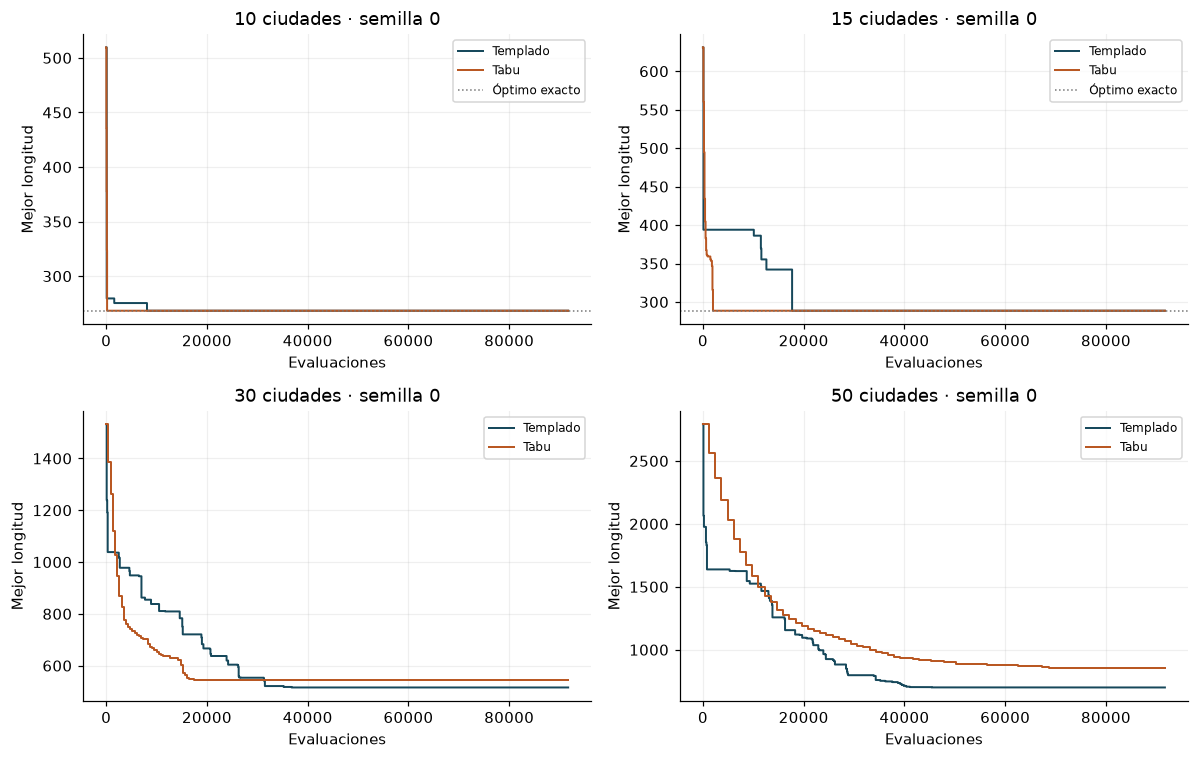

In [12]:
colores = {'Templado': '#16485B', 'Tabu': '#B95722'}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, n in zip(axes.flat, TAMANOS):
    for algoritmo in ['Templado', 'Tabu']:
        h = pd.DataFrame(resultado['historiales_semilla0'][f'{n}_{algoritmo}'])
        ax.step(h.evaluaciones, h.mejor_costo, where='post',
                color=colores[algoritmo], label=algoritmo, linewidth=1.3)
    if str(n) in resultado['optimos']:
        ax.axhline(resultado['optimos'][str(n)]['costo_optimo'], color='#777777',
                   linestyle=':', linewidth=1, label='Óptimo exacto')
    ax.set(title=f'{n} ciudades · semilla 0', xlabel='Evaluaciones', ylabel='Mejor longitud')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(CARPETA / 'resultados/convergencia.png', dpi=140)
plt.show()

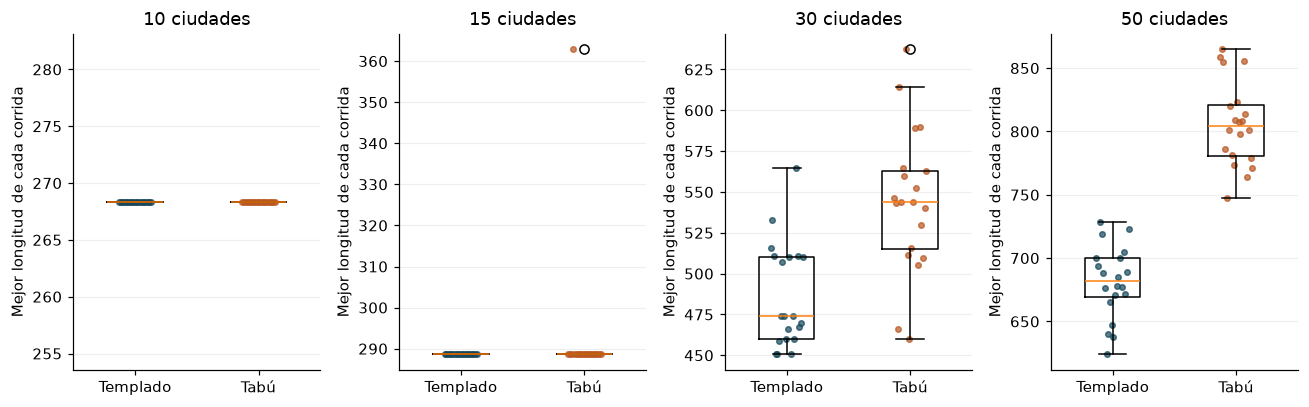

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.8))
for ax, n in zip(axes, TAMANOS):
    grupos = [corridas[(corridas.n == n) & (corridas.algoritmo == a)].mejor_costo.to_numpy()
              for a in ['Templado', 'Tabu']]
    # El argumento labels conserva compatibilidad con Matplotlib de Colab.
    ax.boxplot(grupos, positions=[1, 2], widths=.45)
    ax.set_xticks([1, 2], ['Templado', 'Tabú'])
    for x, grupo in zip([1, 2], grupos):
        desplazamiento = np.linspace(-.13, .13, len(grupo))
        ax.scatter(x + desplazamiento, grupo, s=13,
                   color=colores['Templado' if x == 1 else 'Tabu'], alpha=.7)
    ax.set(title=f'{n} ciudades', ylabel='Mejor longitud de cada corrida')
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(CARPETA / 'resultados/distribucion.png', dpi=140)
plt.show()

## Comparación directa con Tarea 5: 15 ciudades

La siguiente traza muestra los primeros movimientos de tabú de la
semilla cero. Los índices internos se convierten aquí a etiquetas C01,
C02, etc. Una marca aceptada en k vence al terminar k+5.

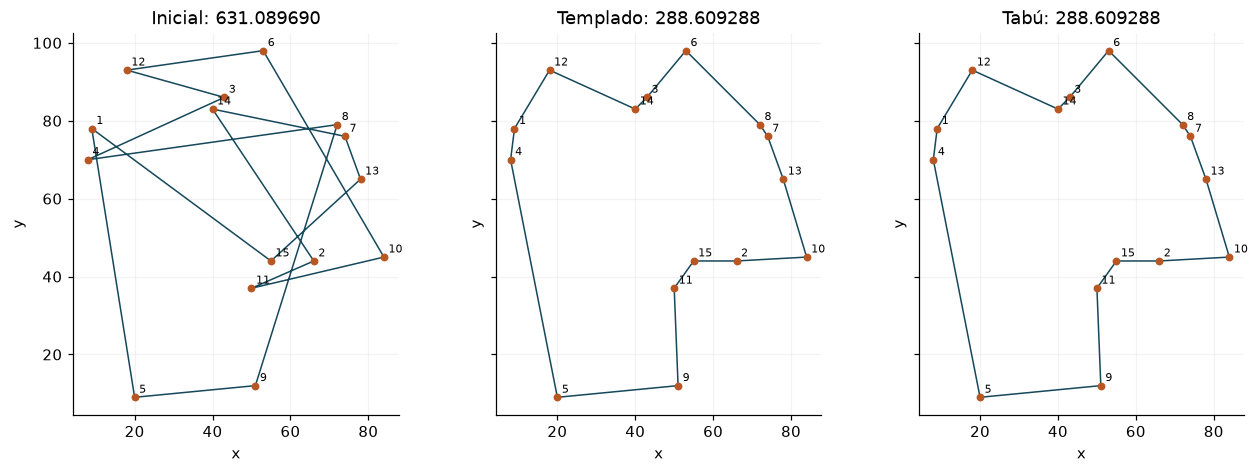

,iteracion,ciudades,tabu_hasta_inclusive,aspiracion,costo_actual,mejor_costo
0,1,C08 ↔ C14,6,False,560.163745,560.163745
1,2,C01 ↔ C09,7,False,494.764954,494.764954
2,3,C12 ↔ C14,8,False,434.172438,434.172438
3,4,C10 ↔ C15,9,False,404.638770,404.638770
4,5,C04 ↔ C12,10,False,382.685920,382.685920
5,6,C01 ↔ C04,11,False,367.396717,367.396717
6,7,C03 ↔ C14,12,False,361.372365,361.372365
7,8,C06 ↔ C14,13,False,360.309753,360.309753
8,9,C11 ↔ C15,14,False,359.134748,359.134748
9,10,C07 ↔ C08,15,False,360.135877,359.134748


mejor_costo              segundos          
algoritmo        Tabu    Templado      Tabu  Templado
semilla                                              
0          288.609288  288.609288  0.264712  0.468137
1          288.609288  288.609288  0.267727  0.527000
2          288.609288  288.609288  0.320020  0.644086
3          362.848480  288.609288  0.262848  0.428882
4          288.609288  288.609288  0.223679  0.445867
5          288.609288  288.609288  0.252457  0.505745
6          288.609288  288.609288  0.275100  0.473327
7          288.609288  288.609288  0.258008  0.399618
8          288.609288  288.609288  0.259670  0.413925
9          288.609288  288.609288  0.274971  0.515722
10         288.609288  288.609288  0.255974  0.459802
11         288.609288  288.609288  0.292269  0.540611
12         288.609288  288.609288  0.262239  0.483441
13         288.609288  288.609288  0.242342  0.518278
14         288.609288  288.609288  0.293742  0.517973
15         288.609288  288.609288  0.381923  0.508932
16         288.609288  288.609288  0.308481  0.502801
17         288.609288  288.609288  0.238180  0.455834
18         288.609288  288.609288  0.249558  0.468870
19         288.609288  288.609288  0.255074  0.504097

In [14]:
r15 = corridas[(corridas.n == 15) & (corridas.semilla == 0)].set_index('algoritmo')
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharex=True, sharey=True)
puntos = coordenadas[:15]
rutas = [r15.loc['Templado', 'ruta_inicial'], r15.loc['Templado', 'mejor_ruta'],
         r15.loc['Tabu', 'mejor_ruta']]
costos = [r15.loc['Templado', 'costo_inicial'], r15.loc['Templado', 'mejor_costo'],
          r15.loc['Tabu', 'mejor_costo']]
for ax, ruta, costo, titulo in zip(axes, rutas, costos, ['Inicial', 'Templado', 'Tabú']):
    cerrada = ruta + ruta[:1]
    ax.plot(puntos[cerrada, 0], puntos[cerrada, 1], linewidth=1, color='#16485B')
    ax.scatter(puntos[:, 0], puntos[:, 1], s=17, color='#B95722', zorder=3)
    for i, (x, y) in enumerate(puntos):
        ax.annotate(f'{i+1}', (x, y), xytext=(3, 3), textcoords='offset points', fontsize=7)
    ax.set(title=f'{titulo}: {costo:.6f}', xlabel='x', ylabel='y', aspect='equal')
    ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(CARPETA / 'resultados/rutas_15.png', dpi=140)
plt.show()
traza = pd.DataFrame(resultado['trazas_tabu']['15'])
traza['ciudades'] = traza.ciudades_intercambiadas_base0.map(
    lambda par: ' ↔ '.join(f'C{i+1:02d}' for i in par))
display(traza[['iteracion', 'ciudades', 'tabu_hasta_inclusive', 'aspiracion',
               'costo_actual', 'mejor_costo']].round(6))
display(corridas[corridas.n == 15][['semilla', 'algoritmo', 'mejor_costo', 'segundos']]
        .pivot(index='semilla', columns='algoritmo').round(6))

In [15]:
s15 = resumen[resumen.n == 15].set_index('algoritmo')
c30 = comparaciones.set_index('n').loc[30]
c50 = comparaciones.set_index('n').loc[50]
conclusion = (
    f"En 15 ciudades, templado alcanzó el óptimo en {int(s15.loc['Templado', 'aciertos_optimo'])}/20 "
    f"corridas y tabú en {int(s15.loc['Tabu', 'aciertos_optimo'])}/20. "
    f"Para 30 ciudades, templado produjo menor costo en {int(c30.templado_mejor)} de 20 parejas; "
    f"para 50, en {int(c50.templado_mejor)} de 20. "
    'Con horizonte cinco y este presupuesto, el templado fue más consistente en calidad al crecer '
    'la instancia. Tabú tuvo menor tiempo mediano en esta implementación. '
    'Al evaluar el vecindario completo, tabú sólo pudo elegir 2038, 874, 211 y 75 movimientos '
    'para 10, 15, 30 y 50 ciudades; el templado propuso 91 700 vecinos en cada tamaño.'
)
display(Markdown(conclusion))
(CARPETA / 'resultados/conclusion.txt').write_text(conclusion, encoding='utf-8')

En 15 ciudades, templado alcanzó el óptimo en 20/20 corridas y tabú en 19/20. Para 30 ciudades, templado produjo menor costo en 18 de 20 parejas; para 50, en 20 de 20. Con horizonte cinco y este presupuesto, el templado fue más consistente en calidad al crecer la instancia. Tabú tuvo menor tiempo mediano en esta implementación. Al evaluar el vecindario completo, tabú sólo pudo elegir 2038, 874, 211 y 75 movimientos para 10, 15, 30 y 50 ciudades; el templado propuso 91 700 vecinos en cada tamaño.

500

## Alcance y archivos

Se estudia **una instancia por tamaño**, con 20 rutas iniciales. Son
instancias anidadas, no 20 mapas independientes. Estos resultados
describen sensibilidad al arranque y a esta configuración; no prueban
superioridad general ni que el número de ciudades sea la única causa.
El horizonte fijo cinco tiene distinto peso relativo en cada tamaño.
La memoria por pares reduce repeticiones recientes de movimientos,
pero no garantiza evitar todos los ciclos de rutas completas.

La búsqueda tabú conserva el mejor ciclo visto aunque el estado final
empeore. El valor mínimo observado para 30 o 50 ciudades se denomina
**mejor encontrado**, no óptimo. Los tiempos variarán al ejecutar en Colab.

Los CSV, JSON, trazas y figuras quedan en `tarea6_resultados/resultados`.
El ZIP generado abajo se puede descargar desde el panel **Archivos**.

Fuentes: presentación 9 de la clase, *Heurísticas modernas*, y Tarea 5
previamente ejecutada;
[Glover (1989), Tabu Search—Part I](https://leeds-faculty.colorado.edu/glover/TS%20-%20Part%20I-ORSA-aw.pdf),
DOI 10.1287/ijoc.1.3.190;
[MathWorks: regla de aceptación del templado](https://www.mathworks.com/help/gads/how-simulated-annealing-works.html);
[Held y Karp: referencia de programación dinámica](https://research.ibm.com/publications/a-dynamic-programming-approach-to-sequencing-problems).

In [16]:
import zipfile
archivo_zip = Path('Resultados_Tarea_6.zip')
with zipfile.ZipFile(archivo_zip, 'w', zipfile.ZIP_DEFLATED) as paquete:
    for archivo in sorted(CARPETA.rglob('*')):
        if archivo.is_file():
            paquete.write(archivo, archivo.relative_to(CARPETA.parent))
print('Resultados guardados en:', archivo_zip)

Resultados guardados en: Resultados_Tarea_6.zip
